# LAB 06 — Attention Mechanism


In [ ]:
import sys, re, time, copy, random, platform, json
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from IPython.display import display, Markdown
from attention_numpy import softmax, scaled_dot_product_attention, entropy, verify_attention

LAB_DIR = Path.cwd() if (Path.cwd() / 'attention_numpy.py').is_file() else Path.cwd() / 'lab6'
sys.path.insert(0, str(LAB_DIR.resolve()))
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')  
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
sns.set_theme(style='whitegrid')
records = []
def record(experiment, setting, metric, value):
    records.append(dict(experiment=experiment, setting=setting, metric=metric, value=float(value)))
print(f'Python {platform.python_version()} | NumPy {np.__version__} | Pandas {pd.__version__}')
print(f'PyTorch {torch.__version__} | device={DEVICE} | threads={torch.get_num_threads()} | seed={SEED}')

Python 3.12.7 | NumPy 1.26.4 | Pandas 2.2.2
PyTorch 2.11.0+cpu | device=cpu | threads=4 | seed=42


#### 17. Bài 7 — Numerical stability

Với $x=[1000,1001,1002]$:

$$m=\max(x)=1002,\qquad x-m=[-2,-1,0].$$
$$\operatorname{softmax}(x)=\frac{[e^{-2},e^{-1},1]}{e^{-2}+e^{-1}+1}
\approx[0.090031,0.244728,0.665241].$$

Phép trừ max không đổi kết quả vì:

$$\frac{e^{x_i-m}}{\sum_j e^{x_j-m}}
=\frac{e^{-m}e^{x_i}}{e^{-m}\sum_j e^{x_j}}
=\frac{e^{x_i}}{\sum_j e^{x_j}}.$$
 

Tại sao phép trừ max(x) không làm thay đổi kết quả softmax?

Cả tử và mẫu cùng nhân với hằng số dương $e^{-\max(x)}$ nên tỷ số không đổi. Sau dịch, số mũ lớn nhất bằng 0, giúp tránh overflow trong ví dụ đã cho. Kết quả vẫn là $[0.090031,0.244728,0.665241]$.

#### 18. Experiment 1 — Attention distribution

Sequence: **“The movie was surprisingly good despite a very slow beginning.”**

 

Context: [[0.18072063 0.11909033]]


,Token,Score (scaled),Attention
0,The,0.070711,0.054199
1,movie,0.141421,0.058171
2,was,0.000000,0.050499
3,surprisingly,0.848528,0.117977
4,good,1.767767,0.295812
5,despite,0.353553,0.071917
6,a,0.000000,0.050499
7,very,0.212132,0.062433
8,slow,1.272792,0.180323
9,beginning,0.141421,0.058171


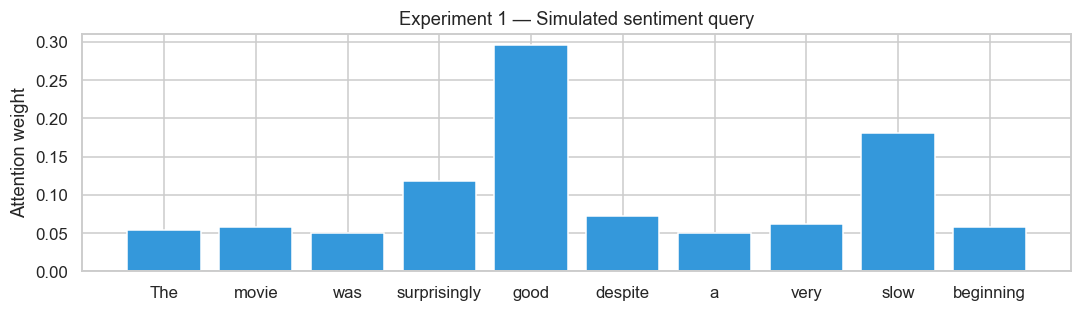

In [ ]:
tokens_demo = 'The movie was surprisingly good despite a very slow beginning'.split()
K_demo = np.array([[.1,.1], [.2,2.5], [.0,.1], [1.2,.1], [2.5,.2],
                   [.5,.3], [.0,.0], [.3,.1], [1.8,.2], [.2,1.3]])
V_demo = np.array([[0,0], [0,1], [0,0], [.5,0], [1,0],
                   [0,.2], [0,0], [.1,0], [-1,0], [0,.8]])
q_sentiment = np.array([[1., 0.]])
s_demo, a_demo, c_demo = scaled_dot_product_attention(q_sentiment, K_demo, V_demo)
display(pd.DataFrame({'Token': tokens_demo, 'Score': s_demo[0], 'Attention': a_demo[0]}))
print('Context:', c_demo)
for token, w in zip(tokens_demo, a_demo[0]): record('exp1', token, 'Attention', w)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(tokens_demo, a_demo[0], color='#3498db')
ax.set(ylabel='Attention weight', title='Experiment 1 — Simulated sentiment query')
plt.tight_layout(); plt.show()

**Model đang phân phối trọng số như thế nào?**

Với query giả lập sentiment $q=[1,0]$, attention phân bố không đều:

| Token | Score | Attention |
|---|---:|---:|
| The | 0.070711 | 0.054199 |
| movie | 0.141421 | 0.058171 |
| was | 0.000000 | 0.050499 |
| surprisingly | 0.848528 | 0.117977 |
| good | 1.767767 | 0.295812 |
| despite | 0.353553 | 0.071917 |
| a | 0.000000 | 0.050499 |
| very | 0.212132 | 0.062433 |
| slow | 1.272792 | 0.180323 |
| beginning | 0.141421 | 0.058171 |

`good` cao nhất (~29.58%), tiếp theo `slow` (~18.03%) và `surprisingly` (~11.80%). Model không chọn duy nhất một token; mọi token không bị mask vẫn nhận weight dương. Tổng weights bằng 1 trước làm tròn. `good` và `slow` có sắc thái khác nhau nhưng cùng có độ tương thích cao với query mô phỏng; dấu đóng góp phụ thuộc V.

Đây là distribution từ các vector tự gán, chưa phải bằng chứng một model đã học được sentiment hay hiểu mệnh đề “despite a very slow beginning”.

#### 19. Experiment 2 — Query thay đổi
 

Sentiment context: [[0.18072063 0.11909033]] | Topic context: [[0.03744326 0.47161058]]
Top sentiment: good | Top topic: movie


,Token,Sentiment query,Topic query
0,The,0.054199,0.062405
1,movie,0.058171,0.340600
2,was,0.050499,0.062405
3,surprisingly,0.117977,0.062405
4,good,0.295812,0.066978
5,despite,0.071917,0.071885
6,a,0.050499,0.058145
7,very,0.062433,0.062405
8,slow,0.180323,0.066978
9,beginning,0.058171,0.145792


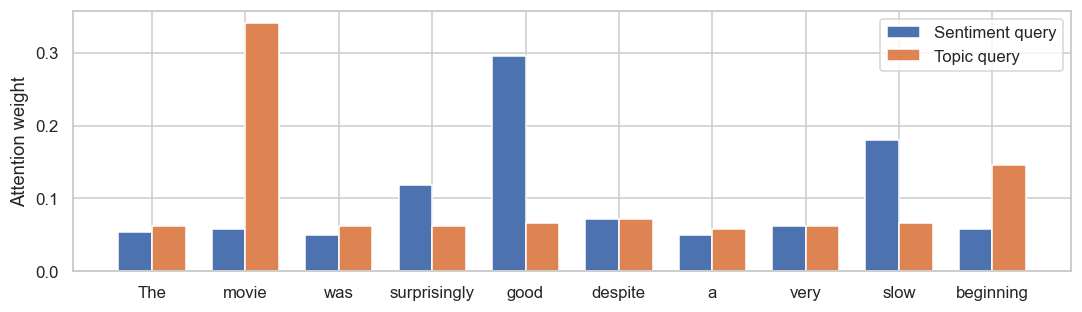

In [ ]:
q_topic = np.array([[0., 1.]])
_, a_topic, c_topic = scaled_dot_product_attention(q_topic, K_demo, V_demo)
display(pd.DataFrame({'Token': tokens_demo, 'Sentiment query': a_demo[0], 'Topic query': a_topic[0]}))
print('Sentiment context:', c_demo, '| Topic context:', c_topic)
print('Top sentiment:', tokens_demo[a_demo[0].argmax()], '| Top topic:', tokens_demo[a_topic[0].argmax()])
for token, w in zip(tokens_demo, a_topic[0]): record('exp2', token, 'Attention (topic)', w)
fig, ax = plt.subplots(figsize=(10, 3))
x = np.arange(len(tokens_demo))
ax.bar(x-.18, a_demo[0], .36, label='Sentiment')
ax.bar(x+.18, a_topic[0], .36, label='Topic')
ax.set_xticks(x, tokens_demo); ax.set_ylabel('Attention weight'); ax.legend()
plt.tight_layout(); plt.show()

*Attention distribution có thay đổi khi query thay đổi không?*

Có trong thí nghiệm này. Giữ nguyên K/V và đổi query $[1,0]$ sang $[0,1]$ cho:

| Token | Query sentiment | Query topic |
|---|---:|---:|
| good | 0.295812 | 0.066978 |
| slow | 0.180323 | 0.066978 |
| movie | 0.058171 | 0.340600 |
| beginning | 0.058171 | 0.145792 |

Token được ưu tiên nhất đổi từ **good** sang **movie**. Nguyên nhân là $s_j=q^Tk_j/\sqrt{d_k}$ phụ thuộc q; đổi q thay đổi tương thích với mỗi key. Vì vậy attention không phải danh sách “từ quan trọng nhất” cố định cho cả câu. Sentiment/topic là tên quy ước của ví dụ tự gán này.

 

#### 21. Self-attention: “I like cats”

**Chọn**

$$X=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix},\quad
W_Q=\begin{bmatrix}1&0\\0&1\end{bmatrix},\quad
W_K=\begin{bmatrix}1&1\\0&1\end{bmatrix},\quad
W_V=\begin{bmatrix}1&0\\1&1\end{bmatrix}.$$

Ba hàng tương ứng `I`, `like`, `cats`. 

**Bước 1: Tạo Q, K, V**

$$Q=XW_Q=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}.$$
$$K=XW_K=\begin{bmatrix}1&1\\0&1\\1&2\end{bmatrix},\qquad
V=XW_V=\begin{bmatrix}1&0\\1&1\\2&1\end{bmatrix}.$$

**Bước 2: Scores**

$$QK^T=\begin{bmatrix}1&0&1\\1&1&2\\2&1&3\end{bmatrix}.$$
$$S=\frac{QK^T}{\sqrt2}\approx
\begin{bmatrix}0.707107&0&0.707107\\0.707107&0.707107&1.414214\\1.414214&0.707107&2.121320\end{bmatrix}.$$

**Bước 3: Softmax theo từng hàng**

$$A\approx\begin{bmatrix}
0.401112&0.197776&0.401112\\
0.248255&0.248255&0.503490\\
0.283995&0.140029&0.575975
\end{bmatrix}.$$

Mỗi hàng có tổng bằng 1 trước khi làm tròn; các hàng không bắt buộc bằng nhau, ma trận không bắt buộc đối xứng.

**Bước 4: Contextual representations**

$$C=AV\approx\begin{bmatrix}
1.401112&0.598888\\
1.503490&0.751745\\
1.575975&0.716005
\end{bmatrix}.$$

Ví dụ $C_{1,:}=0.401112[1,0]+0.197776[1,1]+0.401112[2,1]\approx[1.401112,0.598888]$.

=> representation của mỗi token là tổ hợp value của nhiều token trong cùng sequence. Các con số này minh họa sự tương tác, không chứng minh quan hệ chủ ngữ–động từ–tân ngữ.

Q 
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
K 
 [[1. 1.]
 [0. 1.]
 [1. 2.]]
V 
 [[1. 0.]
 [1. 1.]
 [2. 1.]]
QK^T 
 [[1. 0. 1.]
 [1. 1. 2.]
 [2. 1. 3.]]
S 
 [[0.707107 0.       0.707107]
 [0.707107 0.707107 1.414214]
 [1.414214 0.707107 2.12132 ]]
A 
 [[0.401112 0.197776 0.401112]
 [0.248255 0.248255 0.50349 ]
 [0.283995 0.140029 0.575975]]
C 
 [[1.401112 0.598888]
 [1.50349  0.751745]
 [1.575975 0.716005]]


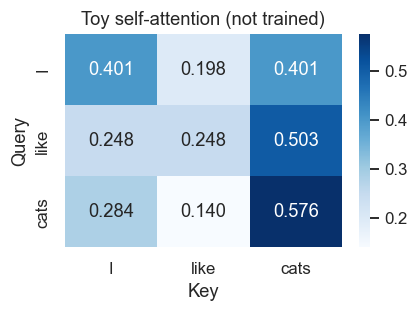

In [6]:
X_toy = np.array([[1.,0.], [0.,1.], [1.,1.]])
WQ = np.eye(2)
WK = np.array([[1.,1.], [0.,1.]])
WV = np.array([[1.,0.], [1.,1.]])
Q_toy, K_toy, V_toy = X_toy @ WQ, X_toy @ WK, X_toy @ WV
S_toy, A_toy, C_toy = scaled_dot_product_attention(Q_toy, K_toy, V_toy)
for name, value in [('Q', Q_toy), ('K', K_toy), ('V', V_toy), ('QK^T', Q_toy @ K_toy.T), ('S', S_toy), ('A', A_toy), ('C', C_toy)]:
    print(name, '\n', value.round(6))
np.testing.assert_allclose(A_toy.sum(axis=-1), 1.)
fig, ax = plt.subplots(figsize=(4, 3))
sns.heatmap(A_toy, annot=True, fmt='.3f', xticklabels=['I','like','cats'], yticklabels=['I','like','cats'], cmap='Blues', ax=ax)
ax.set(xlabel='Key', ylabel='Query', title='Toy self-attention (not trained)')
plt.tight_layout(); plt.show()

#### 22. Attention matrix

Token hiện tại đang attention tới các token nào?

Hàng i ứng với query token i; cột j ứng với key token j. Ô $A_{ij}$ là weight mà query i gán cho value tại j. Mỗi hàng của các token thật có tổng 1, nhưng tổng cột không nhất thiết bằng 1; attention matrix không bắt buộc đối xứng.

| Query / Key | I | like | cats | Nhận xét |
|---|---:|---:|---:|---|
| I | 0.401112 | 0.197776 | 0.401112 | I và cats cùng nhận weight lớn nhất |
| like | 0.248255 | 0.248255 | 0.503490 | cats nhận nhiều weight nhất |
| cats | 0.283995 | 0.140029 | 0.575975 | cats nhận nhiều weight nhất |

Heatmap phía trên biểu diễn đúng ma trận đã tính từ X/W. Mỗi contextual representation là tổng có trọng số của cả ba values; đây là tương tác token-to-token về phép tính, chưa phải kết luận về ngữ pháp.

## 23. Experiment 3 — Attention visualization trên câu có quan hệ ngữ nghĩa

Sử dụng **classifier Attention đã train trên IMDb**. Mỗi hàng là query token, mỗi cột là key token. Các ô là weight sau softmax, không phải xác suất “quan hệ ngữ pháp”. Hai câu ngoài miền review ngắn này không có nhãn chuẩn; chỉ quan sát pattern.

OOV: {'The cat that I adopted yesterday is sleeping.': [], 'The book that I bought yesterday was expensive.': []}


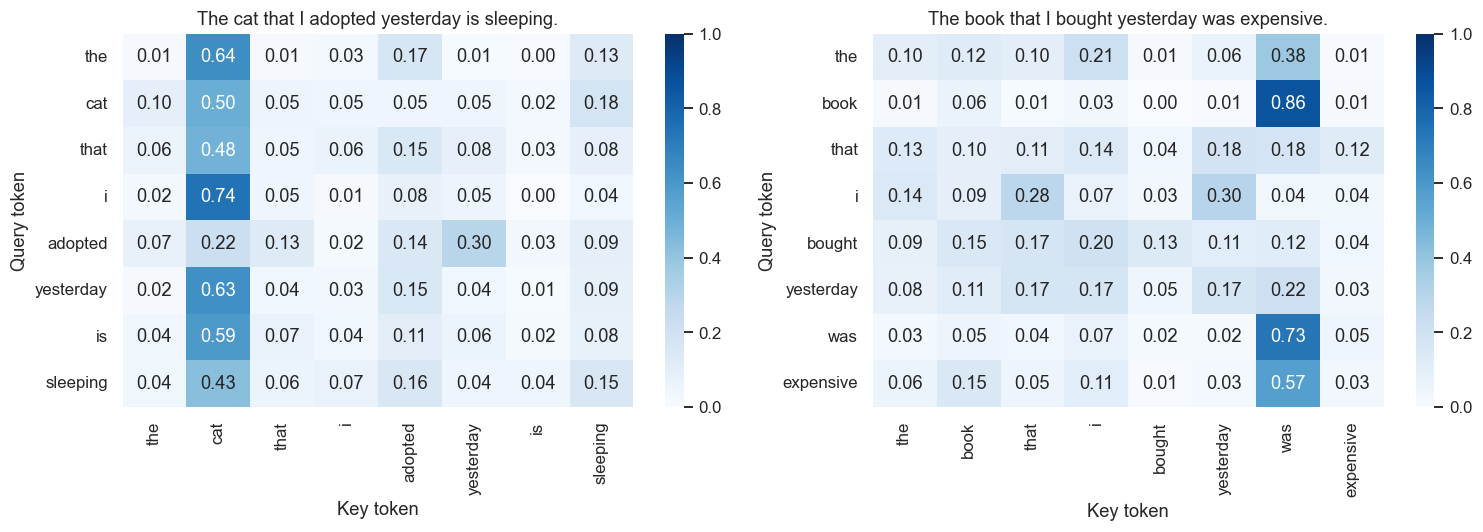

,Query,Top keys
0,cat,"[(cat, 0.500835), (sleeping, 0.182623), (the, ..."
1,adopted,"[(yesterday, 0.296751), (cat, 0.220081), (adop..."
2,sleeping,"[(cat, 0.425782), (adopted, 0.155935), (sleepi..."


In [ ]:
attention_model = models['Attention'].eval()
@torch.no_grad()
def inspect_text(text):
    tokens = tokenize(text)[:MAX_LEN] or ['<UNK>']
    ids = torch.tensor([encode(text)], dtype=torch.long, device=DEVICE)
    logits, a = attention_model(ids, return_attention=True)
    return tokens, float(logits.softmax(-1)[0,1]), a[0,:len(tokens),:len(tokens)].cpu().numpy()

visual_sentences = ['The cat that I adopted yesterday is sleeping.', 'The book that I bought yesterday was expensive.']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
syntax_patterns = []
for ax, sentence in zip(axes, visual_sentences):
    toks, prob, matrix = inspect_text(sentence)
    np.testing.assert_allclose(matrix.sum(-1), 1., atol=1e-6)
    sns.heatmap(matrix, annot=True, fmt='.2f', xticklabels=toks, yticklabels=toks, cmap='Blues', ax=ax, vmin=0, vmax=1)
    ax.set(xlabel='Key token', ylabel='Query token', title=sentence)
    if sentence == visual_sentences[0]:
        for token in ['cat','adopted','sleeping']:
            row = matrix[toks.index(token)]
            top = np.argsort(-row, kind='stable')[:3]
            syntax_patterns.append({'Query':token, 'Top keys':[(toks[j],round(float(row[j]),6)) for j in top]})
plt.tight_layout()
fig.savefig(LAB_DIR / 'attention_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()
display(pd.DataFrame(syntax_patterns))
print('OOV:', {s:[w for w in tokenize(s) if w not in vocab] for s in visual_sentences})

### Mục 23 — cat, adopted, sleeping attention tới những token nào?

**Trả lời:** Với model Attention đã train trên IMDb, top-3 keys của từng query là:

| Query | Key thứ nhất | Key thứ hai | Key thứ ba |
|---|---|---|---|
| cat | cat: 0.500835 | sleeping: 0.182623 | the: 0.095911 |
| adopted | yesterday: 0.296751 | cat: 0.220081 | adopted: 0.144769 |
| sleeping | cat: 0.425782 | adopted: 0.155935 | sleeping: 0.152900 |

**Attention pattern có chứng minh model hiểu ngữ pháp không?**

Không. `sleeping` ưu tiên `cat` phù hợp trực giác về đối tượng đang ngủ, nhưng đây chỉ là một phân phối weight quan sát được. Ở câu thứ hai, query `book` lại đặt khoảng 0.86 vào `was`, không phải `expensive`. Hai câu đều không có OOV, nhưng model được train bằng nhãn sentiment chứ không phải nhãn dependency.

**Attention pattern** mô tả trọng số đã tính. **Linguistic explanation** cần giải thích quan hệ ngôn ngữ và có kiểm chứng bằng dữ liệu/can thiệp thích hợp. Hai heatmap không đủ để khẳng định model hiểu cấu trúc mệnh đề quan hệ hay suy luận như con người.

## 24. Experiment 4 — Dataset và điều kiện so sánh

Experiment 3 dùng heatmap từ classifier đã học nên được chạy sau phần huấn luyện.
Giữ preprocessing và cách chọn subset của LAB 05: bỏ `<br />`, chuẩn hóa khoảng trắng, bỏ duplicate theo text đã clean; stratified split 70/15/15 với seed=42; lấy ngẫu nhiên 10,000 train và 2,000 đầu mỗi tập valid/test sau khi split.
Vocabulary chỉ fit trên 10,000 train, `min_freq=2`. Giữ từ phủ định và apostrophe. Truncate 100 token đầu, right padding PAD=0; UNK=1.

Hai mô hình có cùng dữ liệu, embedding/hidden dimension 64, batch 128, 5 epochs, Adam lr=0.002, dropout=0.3. Chọn checkpoint theo **validation loss thấp nhất**, không dùng test để chọn mô hình. Huấn luyện lại cả LSTM để có phép so sánh cùng máy/cấu hình; không sao chép metric cũ từ LAB 05. Số tham số không ép bằng nhau và sẽ được báo cáo.

In [7]:
def clean_text(text):
    return re.sub(r'\s+', ' ', str(text).replace('<br />', ' ')).strip()
def tokenize(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", clean_text(text).lower().replace('’', "'"))

data_path = LAB_DIR.parent / 'dataset' / 'IMDB Dataset.csv'
raw = pd.read_csv(data_path)
assert not raw[['review', 'sentiment']].isna().any().any(), 'Kiểm tra missing trước khi map label.'
assert set(raw.sentiment.unique()) == {'negative', 'positive'}
df = pd.DataFrame({'text': raw.review.map(clean_text), 'label': (raw.sentiment == 'positive').astype(int), 'source_row': raw.index})
duplicates = int(df.duplicated('text').sum())
df = df.drop_duplicates('text').reset_index(drop=True)
idx_train_full, idx_rest = train_test_split(np.arange(len(df)), train_size=.70, random_state=SEED, stratify=df.label)
idx_valid_full, idx_test_full = train_test_split(idx_rest, train_size=.5, random_state=SEED, stratify=df.label.iloc[idx_rest])
subset = np.random.default_rng(SEED).choice(len(idx_train_full), size=10000, replace=False)
idx_train, idx_valid, idx_test = idx_train_full[subset], idx_valid_full[:2000], idx_test_full[:2000]
assert not (set(idx_train) & set(idx_valid) or set(idx_train) & set(idx_test) or set(idx_valid) & set(idx_test))
train_texts, valid_texts, test_texts = [df.text.iloc[idx].tolist() for idx in (idx_train, idx_valid, idx_test)]
y_train, y_valid, y_test = [df.label.iloc[idx].to_numpy() for idx in (idx_train, idx_valid, idx_test)]
counter = Counter(t for text in train_texts for t in tokenize(text))
words = sorted((w for w, count in counter.items() if count >= 2), key=lambda w: (-counter[w], w))
vocab = {'<PAD>': 0, '<UNK>': 1, **{w:i+2 for i,w in enumerate(words)}}
MAX_LEN, DIM, BATCH_SIZE, EPOCHS, LR = 100, 64, 128, 5, .002

def encode(text, max_length=MAX_LEN):
    ids = [vocab.get(w, 1) for w in tokenize(text)[:max_length]]
    # Chuỗi rỗng dùng UNK để tránh một hàng toàn padding trong softmax.
    ids = ids or [1]
    return ids + [0] * (max_length - len(ids))
def tensor_data(texts, labels):
    return TensorDataset(torch.tensor([encode(t) for t in texts], dtype=torch.long), torch.tensor(labels, dtype=torch.long))
train_ds, valid_ds, test_ds = [tensor_data(t, y) for t, y in [(train_texts,y_train), (valid_texts,y_valid), (test_texts,y_test)]]
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)
lengths = np.array([len(tokenize(t)) for t in train_texts])
data_summary = {'raw': len(raw), 'clean': len(df), 'duplicates': duplicates, 'train':len(train_ds), 'valid':len(valid_ds), 'test':len(test_ds),
                'vocab':len(vocab), 'median_length':float(np.median(lengths)), 'retention':float(np.minimum(lengths,MAX_LEN).sum()/lengths.sum()),
                'truncated_fraction':float((lengths>MAX_LEN).mean())}
print(data_summary)
display(pd.DataFrame([{'Split':name, 'Negative':int((y==0).sum()), 'Positive':int((y==1).sum())} for name,y in [('Train',y_train),('Valid',y_valid),('Test',y_test)]]))
for name, value in data_summary.items(): record('data', 'IMDb', name, value)

{'raw': 50000, 'clean': 49578, 'duplicates': 422, 'train': 10000, 'valid': 2000, 'test': 2000, 'vocab': 33514, 'median_length': 172.0, 'retention': 0.4185697980941158, 'truncated_fraction': 0.8725}


,Split,Negative,Positive
0,Train,4981,5019
1,Valid,992,1008
2,Test,999,1001


### Hai representation

**LSTM:** `Embedding → unidirectional LSTM → h ở token thật cuối cùng → Dropout → Linear(2)`.
Không dùng hidden state ở PAD cuối; lấy output tại `length-1` để loại ảnh hưởng padding tới representation.

**Attention:** `Embedding + sinusoidal position → WQ/WK/WV → scaled dot-product → masked mean of contexts → Dropout → Linear(2)`.
Tự viết phép nhân QKᵀ, softmax, AV bằng PyTorch để autograd; không dùng MultiheadAttention. Mask key PAD trước softmax, đặt output query PAD về 0, mean chỉ chia số token thật. Đây là **single-head self-attention classifier**, chưa phải Transformer hoàn chỉnh (không có FFN/residual/LayerNorm).

In [8]:
class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), DIM, padding_idx=0)
        self.lstm = nn.LSTM(DIM, DIM, batch_first=True)
        self.dropout = nn.Dropout(.3)
        self.classifier = nn.Linear(DIM, 2)
    def forward(self, ids):
        lengths = (ids != 0).sum(1)
        if (lengths == 0).any(): raise ValueError('Chuỗi toàn PAD không hợp lệ.')
        hidden, _ = self.lstm(self.embedding(ids))
        last = hidden[torch.arange(len(ids), device=ids.device), lengths - 1]
        return self.classifier(self.dropout(last))

class AttentionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), DIM, padding_idx=0)
        self.wq, self.wk, self.wv = [nn.Linear(DIM, DIM, bias=False) for _ in range(3)]
        self.dropout = nn.Dropout(.3)
        self.classifier = nn.Linear(DIM, 2)
        pos = torch.arange(MAX_LEN, dtype=torch.float32).unsqueeze(1)
        freq = torch.exp(torch.arange(0, DIM, 2) * (-np.log(10000.) / DIM))
        pe = torch.zeros(MAX_LEN, DIM)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos*freq), torch.cos(pos*freq)
        self.register_buffer('position', pe)
    def forward(self, ids, return_attention=False, use_position=True):
        valid = ids.ne(0)
        if (~valid.any(1)).any(): raise ValueError('Chuỗi toàn PAD không hợp lệ.')
        x = self.embedding(ids)
        if use_position: x = x + self.position[:ids.shape[1]]
        q, k, v = self.wq(x), self.wk(x), self.wv(x)
        scores = q @ k.transpose(-1,-2) / np.sqrt(DIM)
        scores = scores.masked_fill(~valid[:,None,:], float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        weights = weights * valid[:,:,None]  # query PAD không tham gia pool/heatmap
        context = weights @ v
        pooled = context.sum(1) / valid.sum(1, keepdim=True)
        logits = self.classifier(self.dropout(pooled))
        return (logits, weights) if return_attention else logits

# Kiểm chứng NumPy/PyTorch độc lập bằng cùng Q/K/V nhỏ.
qt, kt, vt = [torch.tensor(a, dtype=torch.float64) for a in (Q_toy,K_toy,V_toy)]
at = torch.softmax(qt @ kt.T / np.sqrt(qt.shape[-1]), dim=-1)
np.testing.assert_allclose(at.numpy(), A_toy, atol=1e-12)
np.testing.assert_allclose((at @ vt).numpy(), C_toy, atol=1e-12)
probe = torch.tensor([[2,3,4]], dtype=torch.long)
padded_probe = torch.tensor([[2,3,4,0,0]], dtype=torch.long)
for model_type in [LSTMClassifier, AttentionClassifier]:
    model = model_type().eval()
    with torch.no_grad():
        torch.testing.assert_close(model(probe), model(padded_probe), atol=1e-6, rtol=1e-5)
        if isinstance(model, AttentionClassifier):
            _, weights = model(padded_probe, return_attention=True)
            assert torch.count_nonzero(weights[:,:,3:]) == 0
            assert torch.count_nonzero(weights[:,3:,:]) == 0
            torch.testing.assert_close(weights[:,:3,:].sum(-1), torch.ones(1,3))
print('PASSED: NumPy vs PyTorch; padding invariance; key/query mask; row normalization.')

PASSED: NumPy vs PyTorch; padding invariance; key/query mask; row normalization.


In [9]:
@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    all_prob, all_y, total_loss = [], [], 0.
    for ids, y in loader:
        logits = model(ids.to(DEVICE))
        total_loss += nn.functional.cross_entropy(logits, y.to(DEVICE), reduction='sum').item()
        all_prob.append(logits.softmax(-1)[:,1].cpu().numpy())
        all_y.append(y.numpy())
    prob, y = np.concatenate(all_prob), np.concatenate(all_y)
    pred = (prob >= .5).astype(int)
    return total_loss/len(y), y, pred, prob

models, histories, test_outputs, comparison_rows = {}, {}, {}, []
for name, model_type in [('LSTM', LSTMClassifier), ('Attention', AttentionClassifier)]:
    torch.manual_seed(SEED)
    model = model_type().to(DEVICE)
    # Reset generator cho cùng thứ tự batches ở mỗi mô hình.
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    best_loss, best_state, best_epoch, history = float('inf'), None, None, []
    started = time.perf_counter()
    for epoch in range(1, EPOCHS+1):
        model.train()
        loss_sum = 0.
        for ids, y in train_loader:
            ids, y = ids.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(ids), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            loss_sum += loss.item()*len(y)
        valid_loss, vy, vp, _ = evaluate_model(model, valid_loader)
        history.append({'epoch':epoch, 'train_loss':loss_sum/len(train_ds), 'valid_loss':valid_loss, 'valid_accuracy':accuracy_score(vy,vp)})
        if valid_loss < best_loss:
            best_loss, best_state, best_epoch = valid_loss, copy.deepcopy(model.state_dict()), epoch
        print(f'{name:9s} | epoch={epoch} | train_loss={history[-1]["train_loss"]:.4f} | valid_loss={valid_loss:.4f}', flush=True)
    elapsed = time.perf_counter() - started  # gồm train + validation + lưu best state; không gồm preprocessing/test
    model.load_state_dict(best_state)
    _, yt, yp, probs = evaluate_model(model, test_loader)
    row = {'Model':name, 'Accuracy':accuracy_score(yt,yp), 'Precision':precision_score(yt,yp,zero_division=0),
           'Recall':recall_score(yt,yp,zero_division=0), 'F1':f1_score(yt,yp,zero_division=0),
           'Training time (s)':elapsed, 'Parameters':sum(p.numel() for p in model.parameters()), 'Best epoch':best_epoch}
    comparison_rows.append(row)
    models[name], histories[name], test_outputs[name] = model, history, (yt,yp,probs)
    for metric, value in row.items():
        if metric != 'Model': record('exp4', name, metric, value)
    for metric, value in [('Epochs',EPOCHS),('Max length',MAX_LEN),('Vocabulary size',len(vocab)),('Embedding dimension',DIM),('Batch size',BATCH_SIZE),('Learning rate',LR),('Seed',SEED)]:
        record('exp4', name, metric, value)
comparison = pd.DataFrame(comparison_rows)
display(comparison)

LSTM      | epoch=1 | train_loss=0.6917 | valid_loss=0.6856
LSTM      | epoch=2 | train_loss=0.6413 | valid_loss=0.6469
LSTM      | epoch=3 | train_loss=0.5120 | valid_loss=0.5754
LSTM      | epoch=4 | train_loss=0.3996 | valid_loss=0.6351
LSTM      | epoch=5 | train_loss=0.3094 | valid_loss=0.5863
Attention | epoch=1 | train_loss=0.6553 | valid_loss=0.6045
Attention | epoch=2 | train_loss=0.5340 | valid_loss=0.4993
Attention | epoch=3 | train_loss=0.4152 | valid_loss=0.4737
Attention | epoch=4 | train_loss=0.3293 | valid_loss=0.4740
Attention | epoch=5 | train_loss=0.2548 | valid_loss=0.4999


,Model,Accuracy,Precision,Recall,F1,Training time (s),Parameters,Best epoch
0,LSTM,0.7105,0.674092,0.816184,0.738364,13.556995,2178306,3
1,Attention,0.7775,0.812360,0.722278,0.764675,13.881072,2157314,3


### Mục 24 — Representation của hai model khác nhau ở đâu?

**Trả lời:** LSTM cập nhật state tuần tự $h_t=f(x_t,h_{t-1})$; classifier dùng $h_L$ tại token thật cuối cùng, với L là chiều dài trước padding. Thông tin từ đầu câu phải đi qua các bước cập nhật để ảnh hưởng representation cuối.

Attention tạo Q/K/V từ embedding cộng vị trí, tính context riêng cho từng token $c_i=\sum_j A_{ij}v_j$, rồi masked mean $z=\frac1L\sum_{i=1}^L c_i$ để phân loại. Mỗi query có thể tương tác trực tiếp với mọi key không bị mask. Attention không cần recurrent state; thứ tự từ được bổ sung bằng positional encoding. Cả hai classifier ở bài này cuối cùng vẫn dùng một vector kích thước 64.

| Model | Accuracy | F1 | Training time | Parameters |
|---|---:|---:|---:|---:|
| LSTM | 0.7105 | 0.7384 | 13.56 s | 2,178,306 |
| Attention | 0.7775 | 0.7647 | 13.88 s | 2,157,314 |

Attention tốt hơn về accuracy/F1 trong lần chạy này, nhưng Recall positive thấp hơn (0.7223 so với 0.8162). Hai model đều chọn epoch 3 theo validation loss. Không suy từ bảng này rằng Attention luôn tốt hơn, luôn nhanh hơn hoặc đã chứng minh khả năng xử lý dependency dài, vì chỉ chạy một seed và giới hạn 100 token đầu.

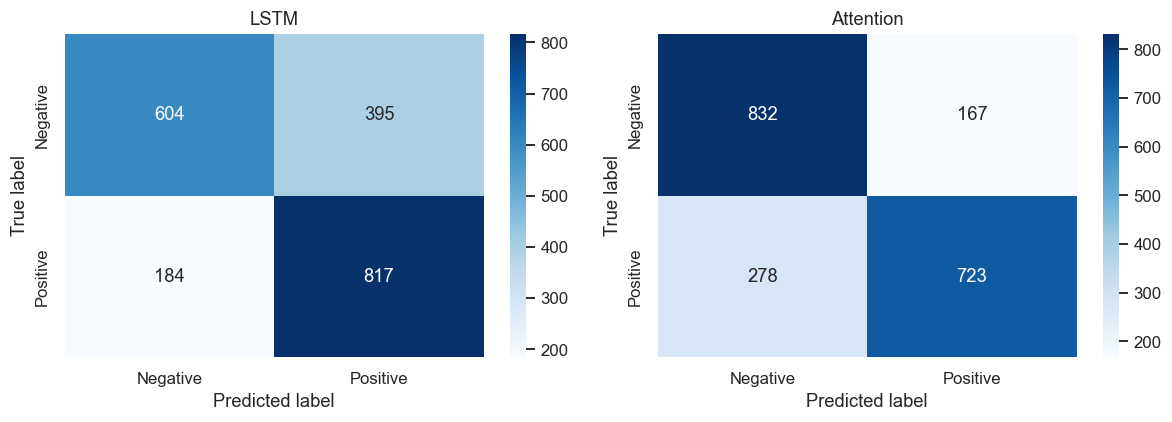

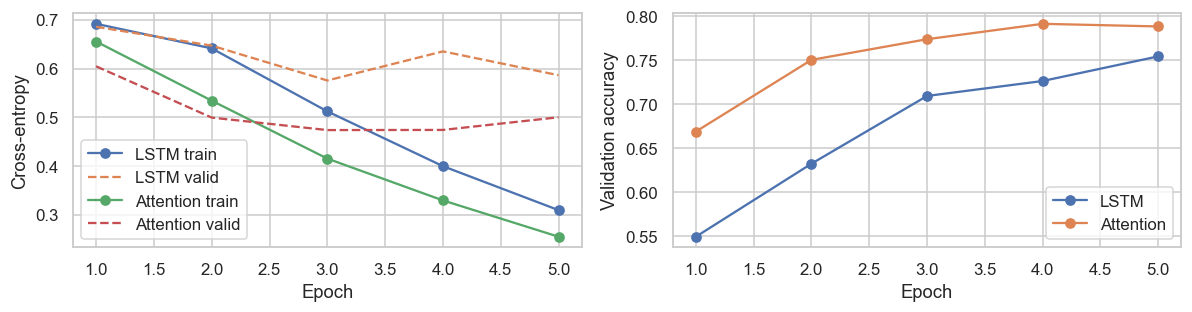

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ['LSTM','Attention']):
    yt, yp, _ = test_outputs[name]
    cm = confusion_matrix(yt, yp, labels=[0,1])
    assert cm.sum() == len(test_ds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative','Positive'], yticklabels=['Negative','Positive'], ax=ax)
    ax.set(xlabel='Predicted label', ylabel='True label', title=name)
plt.tight_layout()
fig.savefig(LAB_DIR / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for name, history in histories.items():
    h = pd.DataFrame(history)
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=f'{name} train')
    axes[0].plot(h.epoch, h.valid_loss, '--', label=f'{name} valid')
    axes[1].plot(h.epoch, h.valid_accuracy, marker='o', label=name)
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy'); axes[0].legend()
axes[1].set(xlabel='Epoch', ylabel='Validation accuracy'); axes[1].legend()
plt.tight_layout(); plt.show()

### Mục 23 — cat, adopted, sleeping attention tới những token nào?

**Trả lời:** Với model Attention đã train trên IMDb, top-3 keys của từng query là:

| Query | Key thứ nhất | Key thứ hai | Key thứ ba |
|---|---|---|---|
| cat | cat: 0.500835 | sleeping: 0.182623 | the: 0.095911 |
| adopted | yesterday: 0.296751 | cat: 0.220081 | adopted: 0.144769 |
| sleeping | cat: 0.425782 | adopted: 0.155935 | sleeping: 0.152900 |

**Attention pattern có chứng minh model hiểu ngữ pháp không?**

Không. `sleeping` ưu tiên `cat` phù hợp trực giác về đối tượng đang ngủ, nhưng đây chỉ là một phân phối weight quan sát được. Ở câu thứ hai, query `book` lại đặt khoảng 0.86 vào `was`, không phải `expensive`. Hai câu đều không có OOV, nhưng model được train bằng nhãn sentiment chứ không phải nhãn dependency.

**Attention pattern** mô tả trọng số đã tính. **Linguistic explanation** cần giải thích quan hệ ngôn ngữ và có kiểm chứng bằng dữ liệu/can thiệp thích hợp. Hai heatmap không đủ để khẳng định model hiểu cấu trúc mệnh đề quan hệ hay suy luận như con người.

### Word order — kiểm tra đặc tính kiến trúc

Hoán vị cùng bộ token “dog bites man” / “man bites dog”. Khi tắt position, logits sau mean pooling phải giống nhau (sai số float). Khi bật position, mô hình **có thể** phân biệt thứ tự. Khác xác suất chưa chứng minh mô hình học được ai cắn ai. Tắt position ở inference là kiểm tra cấu trúc, không phải phép so sánh hai model được train riêng.

In [12]:
ids_order = torch.tensor([encode('dog bites man'), encode('man bites dog')], dtype=torch.long)
with torch.no_grad():
    no_pos = attention_model(ids_order, use_position=False).softmax(-1)[:,1].numpy()
    with_pos = attention_model(ids_order, use_position=True).softmax(-1)[:,1].numpy()
np.testing.assert_allclose(no_pos[0], no_pos[1], atol=1e-6)
display(pd.DataFrame({'Sentence':['dog bites man','man bites dog'], 'P(positive), no position':no_pos, 'P(positive), position':with_pos}))

,Sentence,"P(positive), no position","P(positive), position"
0,dog bites man,0.056659,0.000459
1,man bites dog,0.056659,0.000244


## 25, 29. Experiment 5 — Sequence length và computational cost

Tính số phần tử $T^2$ và bộ nhớ **riêng một attention matrix float32 của một sample, một head**; không phải tổng RAM training. Scores, weights, gradient, Q/K/V và batch còn làm tăng bộ nhớ. Benchmark CPU dưới đây đo QKᵀ → softmax → AV, loại thời gian tạo Q/K/V và projection; warm-up rồi lấy median 5 lần. Không cấp phát ma trận 10,000 × 10,000 chỉ để đếm số phần tử.

In [13]:
cost_rows = []
torch.manual_seed(SEED)
for length in [10,100,500,1000,10000]:
    row = {'Sequence length':length, 'Matrix elements':length**2, 'Matrix float32 MiB':length**2*4/2**20}
    if length <= 1000:
        q,k,v = [torch.randn(length,DIM) for _ in range(3)]
        with torch.no_grad():
            for _ in range(2): _ = torch.softmax(q@k.T/np.sqrt(DIM),dim=-1)@v
            timings = []
            for _ in range(5):
                start = time.perf_counter()
                _ = torch.softmax(q@k.T/np.sqrt(DIM),dim=-1)@v
                timings.append((time.perf_counter()-start)*1000)
        row['Median forward (ms)'] = float(np.median(timings))
    cost_rows.append(row)
    for metric, value in row.items():
        if metric != 'Sequence length': record('exp5', f'T={length}', metric, value)
cost_table = pd.DataFrame(cost_rows)
display(cost_table)
print('10 → 1000: elements ratio =',1000**2/10**2)

10 → 1000: elements ratio = 10000.0


,Sequence length,Matrix elements,Matrix float32 MiB,Median forward (ms)
0,10,100,0.000381,0.0294
1,100,10000,0.038147,0.0612
2,500,250000,0.953674,0.5370
3,1000,1000000,3.814697,2.3687
4,10000,100000000,381.469727,NaN


## 25, 29. Bài 9 — Chi phí full self-attention

| Sequence length T | Attention matrix | Số phần tử | Bộ nhớ một matrix float32 |
|---:|---|---:|---:|
| 10 | 10 × 10 | 100 | 400 bytes |
| 100 | 100 × 100 | 10,000 | 40,000 bytes |
| 500 | 500 × 500 | 250,000 | 1,000,000 bytes |
| 1,000 | 1,000 × 1,000 | 1,000,000 | 4,000,000 bytes |
| 10,000 | 10,000 × 10,000 | 100,000,000 | 400,000,000 bytes |

Tăng T từ 10 lên 1000: T tăng 100 lần, số score tăng $100^2=10,000$ lần. Bộ nhớ bảng trên chỉ tính **một sample, một head, một matrix**; training còn lưu nhiều tensor và gradient. Projection có chi phí $O(Td^2)$; phần full attention $QK^T$ và $AV$ có chi phí $O(T^2d)$ với dimensions cùng bậc d. Với một query cố định, số score là T và chi phí chỉ tuyến tính theo T khi giữ dimension cố định.

**Mục 25 — Tại sao self-attention có vấn đề computational cost khi sequence rất dài?**

**Trả lời:** Mỗi trong T query phải so với T key nên có $T^2$ scores. Cả phép nhân $QK^T$ và tổng hợp $AV$ tăng bậc hai theo T khi dimension cố định; bộ nhớ của full attention matrix cũng tăng $O(T^2)$. Tăng T gấp 10 làm số phần tử ma trận tăng gấp 100. Batch size, nhiều heads, lưu activations và gradients còn làm bộ nhớ training lớn hơn bảng chỉ tính một matrix.

**Mục 29 — Từ T=1000 tới T=10000 cần nhận ra điều gì?**

**Trả lời:** Số phần tử tăng từ 1,000,000 lên 100,000,000, tức 100 lần. Một matrix float32 ở T=10000 cần 400 MB theo hệ thập phân, khoảng 381.47 MiB. Attention có thể tính song song nhưng vẫn tốn tài nguyên; không thể tăng context tùy ý chỉ vì bỏ recurrence.

Benchmark đã chạy cho T=10/100/500/1000 cho median forward lần lượt khoảng 0.0294/0.0612/0.5370/2.3687 ms. Thời gian không tăng đúng tỷ lệ số phần tử vì overhead và hiệu suất tính toán. Không cấp phát ma trận T=10000 trong benchmark; hàng đó là phép tính số phần tử/bộ nhớ lý thuyết.

## 26. Application — Context-aware sentiment

Các nhãn `Expected` do người làm gán theo nghĩa câu để khảo sát hành vi, không thay thế test set IMDb. Hiển thị `P(positive)` và xác suất của nhãn dự đoán. Bar chart dùng **mean theo các query thật** của attention matrix, không gọi đó là attention của riêng một query hay lời giải thích nhân quả.

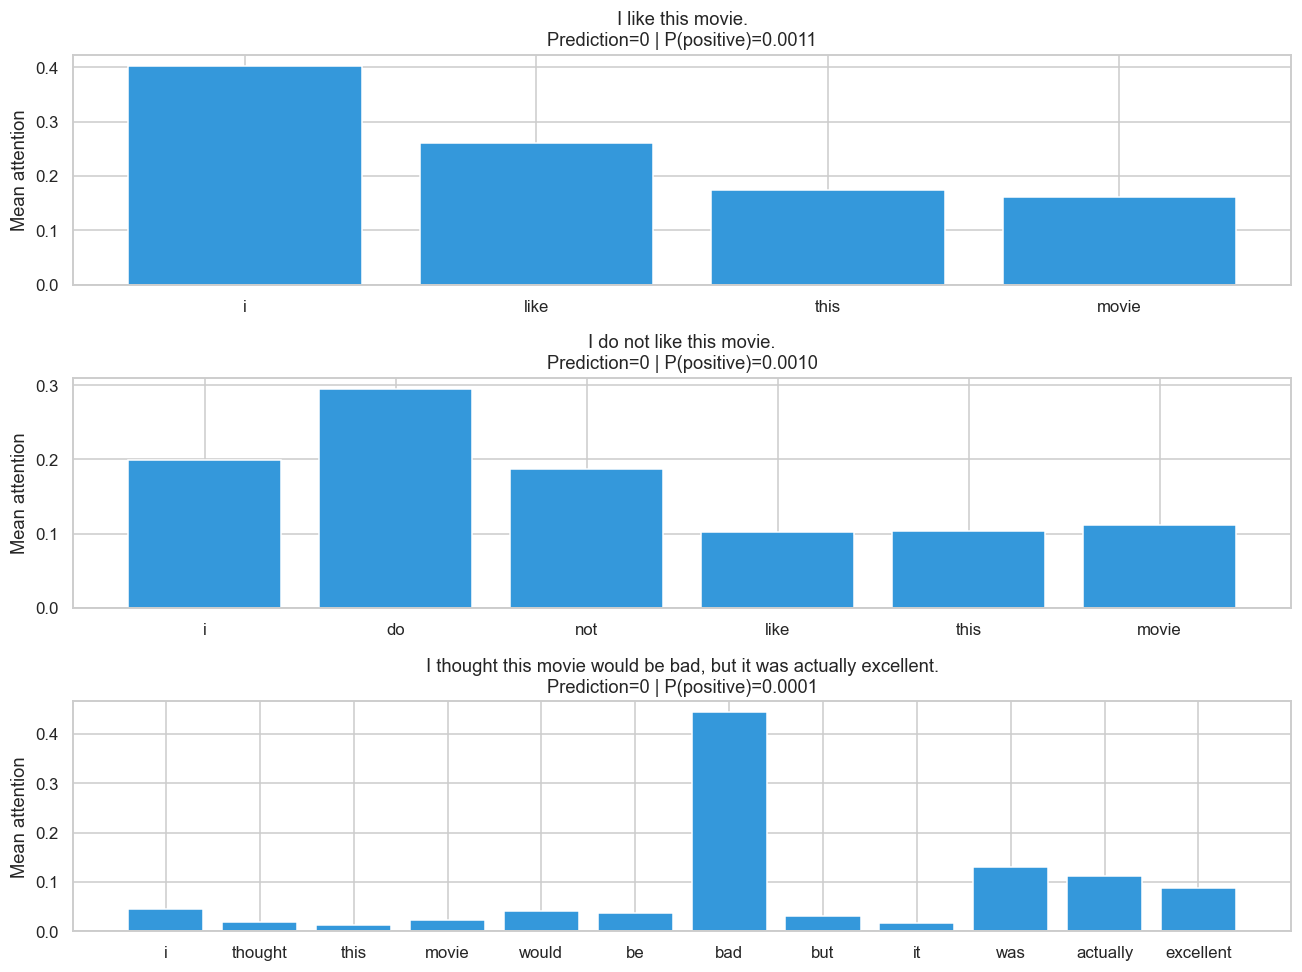

,Text,Expected,Prediction,P(positive),P(predicted label),Correct,Top token
0,I like this movie.,1,0,0.001105,0.998895,False,i
1,I do not like this movie.,0,0,0.000957,0.999043,True,do
2,"I thought this movie would be bad, but it was ...",1,0,0.000087,0.999913,False,bad


In [14]:
app_inputs = [('I like this movie.',1), ('I do not like this movie.',0),
              ('I thought this movie would be bad, but it was actually excellent.',1)]
app_rows = []
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, (sentence, expected) in zip(axes, app_inputs):
    toks, prob, matrix = inspect_text(sentence)
    pred = int(prob >= .5)
    app_rows.append({'Text':sentence, 'Expected':expected, 'Prediction':pred, 'P(positive)':prob,
                     'P(predicted label)':prob if pred else 1-prob, 'Correct':pred==expected,
                     'Top token':toks[matrix.mean(0).argmax()]})
    ax.bar(toks, matrix.mean(0), color='#3498db')
    ax.set(title=f'{sentence}\nPrediction={pred} | P(positive)={prob:.4f}', ylabel='Mean attention')
    for metric, value in [('P(positive)',prob),('Prediction',pred),('Expected',expected)]:
        record('application', sentence, metric, value)
plt.tight_layout(); plt.show()
display(pd.DataFrame(app_rows))

### Mục 26 — Prediction, probability và phân tích đúng/sai

| Câu | Expected | Predicted | P(positive) | Mean-attention cao nhất |
|---|---|---|---:|---|
| I like this movie. | Positive | Negative | 0.001105 | i |
| I do not like this movie. | Negative | Negative | 0.000957 | do |
| I thought this movie would be bad, but it was actually excellent. | Positive | Negative | 0.000087 | bad |

**Mẫu đúng:** Câu thứ hai có label Negative và model dự đoán đúng. Tuy nhiên top token là `do`, còn câu positive bỏ phủ định cũng bị gán Negative. Vì vậy không dùng mẫu đúng này làm bằng chứng model hiểu `not`.

**Mẫu sai thứ nhất:** “I like this movie.” là lời khen rõ nhưng P(positive) rất thấp. Attention cao nhất tại `i` không phù hợp kỳ vọng nhấn vào `like`. Đây là quan sát đi kèm lỗi; chưa có perturbation riêng cho câu này nên không kết luận `i` gây lỗi. Hypothesis đáng kiểm tra là chênh lệch độ dài/phân phối giữa review training và câu cực ngắn, cùng đặc trưng vị trí hoặc từ vựng học được.

**Mẫu sai thứ hai:** Câu cuối đổi từ “would be bad” sang “actually excellent”, label kỳ vọng là Positive. Model tập trung mạnh nhất vào `bad` và vẫn Negative. Pattern phù hợp hypothesis yếu ở contrast, nhưng cần minimal pairs/thay token để kiểm tra trực tiếp; chưa đủ bằng chứng chỉ từ hình.

Ba câu dài lần lượt 4, 6 và 12 token, không bị truncation. Do đó **không thể dùng truncation giải thích các lỗi Application**. Biểu đồ attention cho từng câu và xác suất của nhãn dự đoán được giữ trong notebook.

**Xác suất của nhãn dự đoán là bao nhiêu?** Cả ba câu đều bị model gán Negative, nên xác suất nhãn dự đoán bằng $1-P(positive)$, lần lượt khoảng **0.998895**, **0.999043**, **0.999913**. Xác suất cao không bảo đảm prediction đúng. Các biểu đồ attention của từng câu nằm ngay trong output phía trên.

## 27. Error analysis — 3 correct + 3 incorrect

Chọn ngẫu nhiên có seed cố định **trong từng nhóm đúng/sai** trên test set; giữ source row (chỉ số 0-based trong CSV gốc) để truy lại. In toàn bộ 100 token mà model nhìn thấy, top-5 attention theo vị trí, tỷ lệ UNK và số token bị cắt. Cùng một từ ở hai vị trí vẫn là hai key khác nhau.

Kiểm tra hypothesis bằng cách thay **một vị trí top-attention** thành UNK, rồi đối chiếu với thay **một vị trí thấp-attention**. Chỉ thay ID tại vị trí đó, giữ chiều dài và các vị trí khác. Đây là perturbation kiểm tra độ nhạy; UNK có thể tạo input lệch phân phối, không chứng minh nguyên nhân duy nhất của prediction. Các mẫu đúng/sai này cũng cung cấp ví dụ bổ sung cho Application nếu ba câu cho sẵn không có đủ cả hai nhóm.

In [15]:
yt, yp, probabilities = test_outputs['Attention']
rng = np.random.default_rng(SEED)
chosen = [('C'+str(j+1),int(i)) for j,i in enumerate(rng.choice(np.flatnonzero(yt==yp),3,replace=False))]
chosen += [('E'+str(j+1),int(i)) for j,i in enumerate(rng.choice(np.flatnonzero(yt!=yp),3,replace=False))]
error_examples = []
for name, i in chosen:
    text = test_texts[i]
    tokens, probability, matrix = inspect_text(text)
    avg = matrix.mean(axis=0)
    order = np.argsort(-avg, kind='stable')
    token_ids = encode(text)
    # Chỉ thử thay token biết trong vocab, vì thay UNK bằng UNK không có tác dụng.
    known = [int(j) for j in order if token_ids[j] != 1]
    top, low = known[0], known[-1]
    interventions = []
    for j in [top, low]:
        changed = token_ids.copy(); changed[j] = 1
        with torch.no_grad():
            p_changed = float(attention_model(torch.tensor([changed])).softmax(-1)[0,1])
        interventions.append({'position':j, 'token':tokens[j], 'weight':float(avg[j]), 'p_after':p_changed,
                              'delta_p_positive':p_changed-probability, 'prediction_after':int(p_changed>=.5)})
    example = {'id':name, 'test_index':i, 'source_row':int(df.source_row.iloc[idx_test[i]]),
               'true':int(yt[i]), 'pred':int(yp[i]), 'p_positive':probability, 'total_tokens':len(tokenize(text)),
               'visible_text':' '.join(tokens), 'tail_text':' '.join(tokenize(text)[MAX_LEN:])[:1000],
               'unk_count':sum(t==1 for t in token_ids[:len(tokens)]),
               'top5':[{'position':int(j),'token':tokens[j],'weight':float(avg[j])} for j in order[:5]],
               'interventions':interventions}
    error_examples.append(example)
    display(Markdown(f'### {name} — true={yt[i]}, pred={yp[i]}, P(positive)={probability:.4f}\n\n> '+example['visible_text']))
    display(pd.DataFrame(example['top5']))
    display(pd.DataFrame(interventions))

### C1 — true=1, pred=1, P(positive)=0.9317

> spoiler alert w somerset maugham classic on film about a love obsessed young man who's abused hurt and humiliated by the object of his obsession to the point of losing everything he has only to find true love in the end under the most unusual circumstances leslie howard plays the role of philip carey a sensitive young artiest in paris trying to make a living by selling his paintings told by a local art expert that his work is not at all good enough to be sold to the art going public philip decides to go back to his native

,position,token,weight
0,55,sensitive,0.051704
1,21,object,0.051565
2,44,unusual,0.046289
3,1,alert,0.040710
4,68,paintings,0.026490


,position,token,weight,p_after,delta_p_positive,prediction_after
0,55,sensitive,0.051704,0.899694,-0.032049,1
1,28,of,0.002118,0.925556,-0.006187,1


### C2 — true=1, pred=1, P(positive)=0.8892

> i was stunned by this film i have been renting antonioni's films rediscovering them and this film showed me the climax and fruits of his 50 years of directing what an eye for setting color and detail i have never seen such visual beauty and poetry filmed before i had to stop after the first story and hold back the tears yes beauty moves me like it moved keats to write ode on a grecian urn this movie is made for the mature emotionally and intellectually audience those hoping to see physical action and soap opera will be disappointed i

,position,token,weight
0,62,beauty,0.085191
1,43,beauty,0.082339
2,57,hold,0.036322
3,96,will,0.035949
4,47,before,0.033231


...

,position,token,weight
0,61,horrible,0.131107
1,56,great,0.057684
2,10,high,0.043075
3,81,great,0.035799
4,93,great,0.032687


,position,token,weight,p_after,delta_p_positive,prediction_after
0,61,horrible,0.131107,0.826010,0.388442,1
1,16,aired,0.002722,0.414806,-0.022762,0


### E3 — true=1, pred=0, P(positive)=0.4838

> the gang of roses every rose has its thorns a mix of old western and hip hop blended perfectly together the clothing styles the scenery and the plot are all suited to what the director wanted plot in five years they robbed twenty seven banks and then vanished without a trace now a small western town is under siege and one of the first victims is rachel's sister the rose gang is ready to ride again and this time it's personal rachel michael calhoun chastity lil kim maria lisaraye zang li marie matiko and kim stacey dash five gunslinging women

,position,token,weight
0,5,rose,0.125153
1,69,rose,0.049244
2,18,perfectly,0.044301
3,81,rachel,0.026088
4,67,sister,0.026044


,position,token,weight,p_after,delta_p_positive,prediction_after
0,5,rose,0.125153,0.671500,0.187713,1
1,43,seven,0.002107,0.450219,-0.033568,0


### Mục 27 — Trả lời câu hỏi về attention và lỗi dự đoán


**Attention có tập trung vào token mà sinh viên dự đoán là quan trọng không?**

Không phải lúc nào cũng trùng trực giác. C2 nhấn `beauty` và C3 nhấn `worst`, phù hợp các từ khen/chê rõ. C1 nhấn `sensitive`, `object`, `unusual`, chưa trùng các từ sentiment như `classic`. E1 nhấn `masterpiece` nhưng lời khen thuộc bản phim khác; E2 nhấn `horrible` trong phạm vi “not a lot of …”; E3 nhấn `rose` trong tên/nội dung phim thay vì chỉ tín hiệu khen. Phân tích từng mẫu được trình bày đầy đủ bên dưới.

**Nếu không, điều này có thể giải thích prediction sai không?**

Đây là **hypothesis cần kiểm tra**, không thể kết luận chỉ bằng heatmap. Trong E1/E2/E3, thay vị trí top-attention bằng UNK làm P(positive) lần lượt đổi **0.8003 → 0.4337**, **0.4376 → 0.8260**, **0.4838 → 0.6715** và đều đổi sang nhãn đúng. Thay vị trí low-attention không đổi nhãn trong các mẫu này. Điều đó hỗ trợ hypothesis model nhạy với các từ đã quan sát, nhưng thay token làm thay cả Q/K/V, context và classifier input; chưa cô lập nguyên nhân riêng của attention.

Không kết luận “Attention nhìn sai từ nên model sai”. Cần xét đồng thời nội dung, đối tượng đánh giá, phủ định, truncation, vocabulary và behavior sau can thiệp. UNK cũng có thể tạo input lệch phân phối.

### Thiết lập phân tích

Model chọn checkpoint epoch 3 theo validation loss. Test set có 2,000 review độc lập; Accuracy = **0.7775**, Precision = **0.8124**, Recall = **0.7223**, F1 = **0.7647** với positive=1 và threshold 0.5.

Confusion matrix (hàng = nhãn thật, cột = nhãn dự đoán):

| True / Predicted | Negative | Positive |
|---|---:|---:|
| Negative | 832 | 167 |
| Positive | 278 | 723 |

Chọn ngẫu nhiên 3 mẫu đúng và 3 mẫu sai bằng `np.random.default_rng(42)` trong từng nhóm. `test_index` là chỉ số trong test subset; `source_row` là chỉ số 0-based trong CSV IMDb gốc. Notebook in đủ 100 token mà model nhìn thấy, 5 vị trí attention lớn nhất, số UNK và kết quả perturbation.

**Cách đọc attention:** Attention matrix có một hàng cho mỗi query. Vì classifier mean-pool context, phần này dùng $\bar\alpha_j=\frac1L\sum_{i=1}^L A_{ij}$ để tóm tắt attention nhận tại key j, với L là số token thật. Đây là thống kê trung bình, không phải riêng attention của `[CLS]` hoặc attribution nhân quả. Token ở vị trí khác nhau được giữ riêng, kể cả cùng từ.

**Kiểm tra hypothesis:** Thay một token đã biết trong vocabulary bằng UNK tại vị trí attention cao nhất, rồi làm phép thử riêng ở một vị trí attention thấp nhất. Giữ nguyên chiều dài và vị trí các token khác. Báo cáo P(positive) trước/sau; không train lại sau khi xem các lỗi.

### Bảng 3 correct + 3 incorrect

| Mẫu | test_index / source_row | True → Pred | P(positive) | Độ dài gốc → model thấy | UNK | Top key (vị trí; weight) |
|---|---|---|---:|---|---:|---|
| C1 | 1299 / 10450 | Positive → Positive | 0.9317 | 682 → 100 | 2 | sensitive (55; 0.0517) |
| C2 | 187 / 5130 | Positive → Positive | 0.8892 | 139 → 100 | 3 | beauty (62; 0.0852) |
| C3 | 1544 / 44526 | Negative → Negative | 0.0117 | 639 → 100 | 3 | worst (5; 0.1327) |
| E1 | 147 / 22882 | Negative → Positive | 0.8003 | 108 → 100 | 1 | masterpiece (56; 0.1233) |
| E2 | 1404 / 23537 | Positive → Negative | 0.4376 | 160 → 100 | 1 | horrible (61; 0.1311) |
| E3 | 1710 / 27188 | Positive → Negative | 0.4838 | 171 → 100 | 5 | rose (5; 0.1252) |

Vị trí trong bảng cũng là 0-based. “UNK” chỉ đếm trong phần model nhìn thấy; không đại diện tất cả từ hiếm của review.

### 3.1. C1 — Positive → Positive, P(positive) = 0.9317

- **Trích đoạn model thấy:** “spoiler alert w somerset maugham classic on film about a love obsessed young man who's abused hurt and humiliated … only to find true love in the end …”
- **Nhận xét text:** Review mở bằng tóm tắt cốt truyện, có cả `classic`, `love` và các từ tiêu cực `abused`, `hurt`, `humiliated`. Không thể coi mọi từ mô tả sự kiện buồn là thái độ chê phim.
- **Attention:** Top-3 là `sensitive` (0.0517), `object` (0.0516), `unusual` (0.0463). Chúng không trùng hoàn toàn với các từ sentiment mà người đọc có thể ưu tiên như `classic`.
- **Đối chiếu hành vi:** Thay `sensitive` bằng UNK làm P(positive) **0.9317 → 0.8997**; thay `of` ở vị trí 28 làm **0.9317 → 0.9256**. Cả hai vẫn Positive.
- **Kết luận:** Model đúng dù attention không chỉ tập trung vào từ cảm xúc rõ ràng. Kết quả phù hợp với việc sử dụng nhiều tín hiệu phân tán, nhưng không chứng minh model phân biệt được cốt truyện và đánh giá. Review dài 682 token nên cũng không thể kết luận nó hiểu toàn bộ review.

### 3.2. C2 — Positive → Positive, P(positive) = 0.8892

- **Trích đoạn:** “i was stunned by this film … what an eye for setting color and detail … such visual beauty and poetry … yes beauty moves me …”
- **Nhận xét text:** Nhiều lời khen trực tiếp về hình ảnh, chi tiết và cảm xúc. `disappointed` ở gần cuối phần nhìn thấy nói về khán giả mong chờ phim hành động/soap opera, không phải kết luận chính của tác giả.
- **Attention:** Hai vị trí `beauty` nhận **0.0852** và **0.0823**, khá phù hợp trực giác về tín hiệu khen ngợi. Top tiếp theo là `hold` (0.0363), không tự mang sentiment rõ ràng.
- **Đối chiếu hành vi:** Thay một vị trí `beauty` làm P(positive) **0.8892 → 0.8744**; thay `of` ở vị trí 27 làm **0.8892 → 0.8799**. Không đổi nhãn.
- **Kết luận:** Có tín hiệu phù hợp giữa text, attention và prediction. Mức thay đổi nhỏ khi thay một `beauty` có thể do còn vị trí `beauty` thứ hai và nhiều lời khen khác; chưa đủ cơ sở gán toàn bộ prediction cho một token.

### 3.3. C3 — Negative → Negative, P(positive) = 0.0117

- **Trích đoạn:** “the twins effect is the worst movie i've seen … the support weak … the weakest vampire … your role in this movie was disappointing …”
- **Nhận xét text:** Lời chê rõ, nhiều tín hiệu cùng chiều ngay trong 100 token đầu. Không cần đọc hết 639 token để thấy bằng chứng tiêu cực ở phần đầu.
- **Attention:** `worst` cao nhất (**0.1327**), tiếp theo `too` (0.0761), `whatsoever` (0.0368).
- **Đối chiếu hành vi:** Thay `worst` làm P(positive) **0.0117 → 0.0628**; thay `seen` ở vị trí 37 làm **0.0117 → 0.0116**. Model vẫn Negative.
- **Kết luận:** Thay từ sentiment mạnh tạo thay đổi lớn hơn đối chứng thấp-attention, phù hợp hypothesis `worst` có liên quan tới prediction. Không đổi nhãn cũng phù hợp với việc có nhiều từ chê khác; không suy ra model đã hiểu mọi cấu trúc phủ định.

### 4.1. E1 — False Positive: nhầm đối tượng lời khen trong câu so sánh

- **True:** Negative. **Pred:** Positive. **P(positive):** 0.8003.
- **Trích đoạn:** “why did they have to make such a dreadful adaptation … a huge disappointment … the 1999 movie release based on the same novel seems like a masterpiece compared to this …”
- **Phân loại lỗi:** **Ambiguous wording / contrast / phạm vi đánh giá**; có yếu tố truncation nhưng chưa đủ để quy là nguyên nhân chính.
- **Hypothesis từ text:** `masterpiece` khen bản phim năm 1999 khi so với bản đang bị chê. Một model nhạy với từ đơn lẻ có thể gán sắc thái tích cực của phim được đem ra so sánh cho review hiện tại. Ngay đầu câu đã có `dreadful adaptation`, `disappointment`, `miscast`, `no chemistry` nên thông tin tiêu cực không hoàn toàn nằm ở phần bị cắt.
- **Attention có phù hợp trực giác không?** Top key là `masterpiece` ở vị trí 56, weight **0.1233**. Tuy nhiên `dreadful` cũng đứng thứ hai (**0.0543**), vì vậy không chính xác nếu nói model hoàn toàn không attention tới lời chê. Người đọc cần xét đối tượng và cụm “compared to this”, không chỉ cực tính từ.
- **Đối chiếu model behavior:** Thay `masterpiece` tại vị trí 56 bằng UNK làm P(positive) **0.8003 → 0.4337**, đổi nhãn sang **Negative**. Thay `there's` tại vị trí 32 (weight 0.0016) làm **0.8003 → 0.7895**, vẫn Positive.
- **Kết luận:** Có bằng chứng độ nhạy với đúng vị trí `masterpiece` được quan sát trên heatmap, hỗ trợ hypothesis nhầm phạm vi lời khen. Đây chưa phải chứng minh “attention nhìn sai nên model sai”: thay token làm thay cả Q/K/V, và can thiệp UNK không giữ nguyên nghĩa câu.

### 4.2. E2 — False Negative: negation và chuyển ý

- **True:** Positive. **Pred:** Negative. **P(positive):** 0.4376.
- **Trích đoạn:** “i didn't think i would like it at all but with john ritter in it … i liked the acting was great not a lot of horrible 2nd rated comedy lines … this was a great show …”
- **Phân loại lỗi:** **Negation**, **contrast**, ngôn ngữ khẩu ngữ; không đủ bằng chứng kết luận lỗi long-range dependency.
- **Hypothesis từ text:** “didn't think … but …” chuyển từ kỳ vọng tiêu cực sang trải nghiệm tốt. `horrible` nằm trong “not a lot of horrible …”, không phải lời chê đơn giản. Review chứa nhiều `great` ngay trong phần nhìn thấy.
- **Attention:** `horrible` cao nhất (**0.1311**); ba vị trí `great` cũng nằm trong top-5 (0.0577, 0.0358, 0.0327). Phân phối có cả tín hiệu tích cực và tiêu cực, nên cần kiểm tra behavior thay vì chỉ đếm token sentiment.
- **Đối chiếu model behavior:** Thay `horrible` ở vị trí 61 làm P(positive) **0.4376 → 0.8260**, chuyển sang **Positive**. Thay `aired` ở vị trí 16 (weight 0.0027) làm **0.4376 → 0.4148**, vẫn Negative.
- **Kết luận:** Phép thử hỗ trợ hypothesis model nhạy với từ tiêu cực nhưng xử lý phủ định/chuyển ý chưa tốt. Không thể quy lỗi chỉ cho một attention weight; cần minimal pairs có kiểm soát và nhiều can thiệp hơn để kiểm tra phạm vi phủ định.

### 4.3. E3 — False Negative: plot summary, truncation và từ ngoài vocabulary

- **True:** Positive. **Pred:** Negative. **P(positive):** 0.4838, gần threshold 0.5.
- **Trích đoạn đầu:** “the gang of roses every rose has its thorns … hip hop blended perfectly together … the clothing styles the scenery and the plot are all suited …” rồi chuyển sang tóm tắt vụ cướp và các nhân vật.
- **Phần sau token 100:** “… i gave it 10 10 because the characters plot and scenery made it for me”. Model **không nhìn thấy** lời kết luận rõ này.
- **Phân loại lỗi:** **Truncation**, **ambiguous wording / plot summary**, **rare word / OOV** (5 UNK trong 100 token). OOV là quan sát về vocabulary, chưa phải bằng chứng riêng về nguyên nhân lỗi.
- **Attention:** `rose` ở vị trí 5 cao nhất (**0.1252**), một `rose` khác đứng thứ hai (0.0492); `perfectly` đứng thứ ba (0.0443). Tên/phần mô tả nội dung nhận nhiều attention hơn một tín hiệu khen rõ.
- **Đối chiếu model behavior:** Thay `rose` vị trí 5 làm P(positive) **0.4838 → 0.6715**, chuyển sang **Positive**. Thay `seven` vị trí 43 (weight 0.0021) làm **0.4838 → 0.4502**, vẫn Negative.
- **Kết luận:** Model nhạy với một từ liên quan chủ đề/tên phim; kết luận tích cực phía sau bị truncation là yếu tố có thể góp phần. Không khẳng định lỗi “100% do truncation”: câu đầu đã có “blended perfectly together”, và chưa có thí nghiệm train/evaluate lại với context dài hơn để cô lập tác động của truncation.

### Đối chiếu perturbation

| Mẫu | P(positive) gốc | Thay top token → P mới | ΔP | Thay low token → P mới | ΔP | Top thay đổi nhãn? |
|---|---:|---|---:|---|---:|---|
| C1 | 0.9317 | sensitive → 0.8997 | −0.0320 | of → 0.9256 | −0.0062 | Không |
| C2 | 0.8892 | beauty → 0.8744 | −0.0148 | of → 0.8799 | −0.0092 | Không |
| C3 | 0.0117 | worst → 0.0628 | +0.0511 | seen → 0.0116 | −0.0001 | Không |
| E1 | 0.8003 | masterpiece → 0.4337 | −0.3666 | there's → 0.7895 | −0.0108 | Có |
| E2 | 0.4376 | horrible → 0.8260 | +0.3884 | aired → 0.4148 | −0.0228 | Có |
| E3 | 0.4838 | rose → 0.6715 | +0.1877 | seven → 0.4502 | −0.0336 | Có |

Trong sáu ví dụ này, thay top-attention token làm xác suất thay đổi nhiều hơn thay vị trí low-attention đối chứng. Chỉ có sáu mẫu và một đối chứng mỗi mẫu nên không suy rộng thành quy luật cho mọi token/review. `ΔP` đo độ nhạy của **toàn mô hình** khi thay input, không tách riêng phần đóng góp của attention, value và classifier.

### Phân loại đầy đủ các nhóm lỗi trong đề

| Nhóm | Bằng chứng / phạm vi kết luận |
|---|---|
| Negation | E2 và cặp có/không `not` ở Application cho thấy cần kiểm tra phạm vi phủ định |
| Long-range dependency | Chưa có phép thử cô lập độ dài dependency; review dài không tự chứng minh lỗi loại này |
| Ambiguous wording | E1 có so sánh hai phiên bản phim; E3 xen plot summary với đánh giá |
| Sarcasm | Chưa có mẫu rõ đủ để gán nhãn chắc chắn trong 6 ví dụ được chọn |
| Rare word | E3 có 5 UNK; cần kiểm tra embedding/vocabulary riêng để quy tác động |
| Domain shift | Application là câu ngắn tự viết, khác phân phối review; đây là hypothesis về distribution shift, không phải thay hẳn miền sentiment |
| Truncation | Cả 6 review dài hơn 100; E3 có lời kết luận tích cực bị cắt, nhưng chưa cô lập hiệu ứng |
| Noise | E2 có khẩu ngữ/cách viết không chuẩn; chưa chạy normalization ablation nên không quy lỗi riêng cho noise |

**Giới hạn:** Mẫu đã được chọn theo đúng/sai nên không đại diện tần suất lỗi toàn test set. Phân loại lỗi là nhận định thủ công, có thể chồng lấn. Các can thiệp chỉ kiểm tra độ nhạy cục bộ, không được dùng để chọn lại checkpoint hoặc tối ưu trên test.

## Tổng hợp kết quả định lượng

Giữ format `experiment,setting,metric,value` của các lab trước. F1/Precision/Recall dùng lớp positive=1, threshold 0.5. `Training time (s)` gồm train + validation + giữ best checkpoint, không gồm đọc dữ liệu, tokenization và test. Các histogram/learning curves/application chart được giữ trong output notebook; hai hình chính lưu riêng theo cấu trúc bài nộp.

In [16]:
results = pd.DataFrame(records, columns=['experiment','setting','metric','value'])
assert not results.duplicated(['experiment','setting','metric']).any()
assert np.isfinite(results.value).all()
results.to_csv(LAB_DIR / 'results.csv', index=False)
display(results[results.experiment == 'exp4'])
print(f'Saved {len(results)} metrics to {LAB_DIR / "results.csv"}')

Saved 91 metrics to D:\HUS\NLP\lab06\results.csv


,experiment,setting,metric,value
40,exp4,LSTM,Accuracy,7.105000e-01
41,exp4,LSTM,Precision,6.740924e-01
42,exp4,LSTM,Recall,8.161838e-01
43,exp4,LSTM,F1,7.383642e-01
44,exp4,LSTM,Training time (s),1.355700e+01
45,exp4,LSTM,Parameters,2.178306e+06
46,exp4,LSTM,Best epoch,3.000000e+00
47,exp4,LSTM,Epochs,5.000000e+00
48,exp4,LSTM,Max length,1.000000e+02
49,exp4,LSTM,Vocabulary size,3.351400e+04


### Dữ liệu đối chiếu cho báo cáo

Các số dưới đây được xuất trực tiếp từ lần chạy để kiểm tra `error_analysis.md` và `reflection.md`. Không điền metric giả định nếu chưa chạy training. Nếu chạy lại với môi trường/siêu tham số khác, cần cập nhật hai báo cáo theo output mới.

In [17]:
evidence = {'data':data_summary, 'comparison':comparison_rows, 'histories':histories,
            'syntax_patterns':syntax_patterns, 'application':app_rows, 'error_examples':error_examples,
            'cost':cost_rows, 'order_no_position':no_pos.tolist(), 'order_position':with_pos.tolist()}
print(json.dumps(evidence, ensure_ascii=False, indent=2))

{
  "data": {
    "raw": 50000,
    "clean": 49578,
    "duplicates": 422,
    "train": 10000,
    "valid": 2000,
    "test": 2000,
    "vocab": 33514,
    "median_length": 172.0,
    "retention": 0.4185697980941158,
    "truncated_fraction": 0.8725
  },
  "comparison": [
    {
      "Model": "LSTM",
      "Accuracy": 0.7105,
      "Precision": 0.6740924092409241,
      "Recall": 0.8161838161838162,
      "F1": 0.7383642114776322,
      "Training time (s)": 13.556995099999767,
      "Parameters": 2178306,
      "Best epoch": 3
    },
    {
      "Model": "Attention",
      "Accuracy": 0.7775,
      "Precision": 0.8123595505617978,
      "Recall": 0.7222777222777222,
      "F1": 0.7646747752511899,
      "Training time (s)": 13.881072099997255,
      "Parameters": 2157314,
      "Best epoch": 3
    }
  ],
  "histories": {
    "LSTM": [
      {
        "epoch": 1,
        "train_loss": 0.6917104748725891,
        "valid_loss": 0.6856211833953857,
        "valid_accuracy": 0.5495
      },

## 28. So sánh LAB 05 và LAB 06

| Property | RNN / LSTM / GRU | Self-attention trong bài |
|---|---|---|
| Sequence order | Có do recurrence | Có nhờ positional encoding; attention thuần không tự biết vị trí |
| Hidden state | Cập nhật từng timestep | Không cần recurrent hidden state |
| Sequential computation | Bước sau phụ thuộc bước trước | Q/K/V và các hàng attention tính song song được |
| Direct token-to-token interaction | Truyền qua chuỗi hidden states | Mỗi query truy cập mọi key không bị mask |
| Long-range interaction | Đường truyền dài, gates giúp giữ thông tin | Đường tương tác trực tiếp; vẫn cần học weight hữu ích |
| Cost theo sequence length | Gần tuyến tính khi dimension cố định | $O(T^2d)$ cho full attention; projection còn $O(Td^2)$ |
| Context representation | Hidden state tại token thật cuối | Mean của các weighted combinations of values |

**Câu hỏi: Attention giải quyết vấn đề gì của recurrent processing?**

**Trả lời:** Giảm sự phụ thuộc vào việc truyền thông tin qua từng bước và cho phép truy cập trực tiếp nhiều token khi tạo context. Representation cuối vẫn có kích thước cố định sau pooling; attention không loại bỏ mọi hình thức nén thông tin.

**Câu hỏi: Attention tạo ra vấn đề mới nào?**

**Trả lời:** Chi phí bậc hai, cần thông tin vị trí, mask đúng, hạn chế truncation, khả năng tập trung vào đặc trưng không phù hợp. Attention không tự bảo đảm hiểu phủ định, ngữ pháp hoặc luôn thắng LSTM.

## Reflection — Đối chiếu dự đoán và kết quả

**Những predictions nào phù hợp hoặc không phù hợp với thực nghiệm? Vì sao?**

| Dự đoán ban đầu | Kết quả thực tế | Nhận xét & Đánh giá |
|---|---|---|
| **Prediction 1:** Key có score lớn nhất nhận weight lớn nhất | Với scores [1,2,3], weights = [0.090031,0.244728,0.665241] | **Phù hợp.** Weight lớn nhất là 0.665241, chưa phải toàn bộ trọng số. Kết luận trong cùng một hàng, không mask key đó, temperature dương. |
| **Prediction 2:** Scores [1,1,1,1] cho phân phối đều | Weights = [0.25,0.25,0.25,0.25] | **Phù hợp.** Query không ưu tiên key nào theo score đã cho; entropy = ln(4). |
| **Prediction 3:** Scores [1,1,10] làm attention tập trung gần hết ở token thứ ba | Weights ≈ [0.00012338,0.00012338,0.99975324] | **Phù hợp.** Token thứ ba nhận khoảng 99.9753%, không bằng 100% về mặt toán học. |
| **Prediction 4:** Tăng 10 → 1000 token làm ma trận self-attention tăng 10,000 lần | Số phần tử tăng 100 → 1,000,000; median forward CPU tăng khoảng 0.0294 → 2.3687 ms | **Đúng về số phần tử.** Runtime tăng khoảng 80.57 lần trong benchmark này, không phải 10,000 lần vì overhead và hiệu suất phép nhân ma trận. Một query cố định chỉ tăng số score 100 lần. |
| **Prediction 5:** Attention không luôn trùng từ quan trọng theo con người | Mẫu E1 đặt weight cao ở `masterpiece` dù lời khen hướng tới bản phim khác; E2 nhấn `horrible` trong “not a lot of horrible…”; câu “I like this movie” nhấn `i` | **Phù hợp với các ví dụ quan sát được.** Heatmap chưa đủ chứng minh nguyên nhân lỗi; perturbation trong E1/E2 cung cấp thêm bằng chứng về độ nhạy của model. |

Năm dự đoán đều phù hợp trong phạm vi đã nêu. Ba câu đầu dựa trên tính chất toán học nên đây là kiểm chứng phép tính; không coi chúng là bằng chứng tổng quát về chất lượng NLP. Không sửa lại dự đoán ban đầu để khớp output.

### Model có dấu hiệu overfitting không? Checkpoint được chọn như thế nào?

Cả hai model chọn **epoch 3 theo validation loss**:

- LSTM: train loss tiếp tục giảm 0.5120 → 0.3094 từ epoch 3 tới 5, nhưng validation loss tăng 0.5754 → 0.5863, có dao động mạnh ở epoch 4 (0.6351).
- Attention: train loss giảm 0.4152 → 0.2548, validation loss tăng 0.4737 → 0.4999. Validation accuracy lại cao hơn ở epoch 4, nhưng quy tắc lựa chọn đã cố định theo loss nên vẫn dùng epoch 3.

Đây là dấu hiệu khoảng cách train/validation tăng, phù hợp với khả năng overfitting và/hoặc confidence kém hiệu chỉnh hơn. Không xem test trong quá trình chọn checkpoint. Số đo chỉ một seed, chưa đủ đánh giá độ ổn định hay ý nghĩa thống kê của chênh lệch hai mô hình.

### Kết quả nào bất ngờ và cần rút ra điều gì?

Attention đạt test accuracy cao hơn LSTM nhưng vẫn sai câu rất ngắn “I like this movie.” và câu chuyển ý “would be bad, but ... actually excellent”. Câu có `not` được dự đoán đúng, nhưng câu bỏ `not` cũng bị gán Negative, nên chưa thể kết luận model hiểu phủ định. Các câu Application không bị cắt; một hypothesis cần kiểm tra thêm là độ dài/phân phối câu khác review training và các tín hiệu từ vựng/vị trí model đã học.

Perturbation của ba mẫu sai làm đổi nhãn khi thay token top-attention, hỗ trợ giả thuyết về độ nhạy từ vựng. Tuy nhiên không suy rộng sáu mẫu thành quy luật toàn test set, và không đồng nhất attention weight với lời giải thích nhân quả.

### Attention là bước chuyển tiếp tới Transformer như thế nào?

LAB 06 làm rõ cơ chế cốt lõi Q/K/V → scores → softmax → context. Transformer kết hợp nhiều heads, position, feed-forward blocks, residual connections và normalization để xây dựng các lớp contextual representation sâu hơn. Classifier một head trong bài không đại diện cho hiệu năng Transformer pretrained.

Nếu tiếp tục phát triển bài: đánh giá nhiều seed; chọn hyperparameters trên validation; kiểm tra riêng negation/contrast và nhóm độ dài; thử positional encoding/mean pooling bằng các model được train riêng; tăng context có kiểm soát và so sánh nhiều cách truncation. Với error analysis, có thể thêm nhiều perturbation giữ nghĩa hoặc thay từ đối chứng thay vì chỉ UNK. Các hướng này chưa được chạy trong kết quả đang báo cáo.